# theme-alpha-q1 Practice: 强势主题延续 + RiskParity

本 notebook 新建为 Q6 practice，不修改旧 notebook。

基准策略固定为 Q3 已确认的原三资产 RiskParity：

- `510300.SS`: 沪深300 ETF
- `513100.SS`: 纳指100 ETF
- `518880.SS`: 黄金 ETF

本次新增假设：2025 年强势主题在 2026 年存在趋势延续，科技、有色、黄金仍有相对强度。

主题候选池：

- `513100.SS`: 纳指100 ETF
- `512400.SS`: 有色金属 ETF
- `159995.SZ`: 芯片 ETF
- `515880.SS`: 通信 ETF
- `518880.SS`: 黄金 ETF

组合方式先试五类：等权、RiskParity、低波动/趋势过滤后的 RiskParity、动量、SuperTrend。

评估窗口：

- 2026 年至今
- 2025 年至今

对比基准包括：原三资产 RiskParity、沪深300、60/40 沪深300/黄金、纯纳指、纯黄金；中证全指和偏股基金指数会优先尝试真实指数数据，若免费源不可得则记录为 unavailable，不用相邻概念替代。


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q1-strong-theme-screening")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2024-01-01"  # warmup for MA/momentum/SuperTrend before 2025/2026 evaluation windows
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
REBALANCE_DAYS = 10
INITIAL_NAV = 100.0

BASELINE_ASSETS = ("510300.SS", "513100.SS", "518880.SS")
THEME_ASSETS = ("513100.SS", "512400.SS", "159995.SZ", "515880.SS", "518880.SS")
ALL_YF_SYMBOLS = tuple(dict.fromkeys(BASELINE_ASSETS + THEME_ASSETS))

SYMBOL_NAMES = {
    "510300.SS": "沪深300ETF",
    "513100.SS": "纳指100ETF",
    "512400.SS": "有色金属ETF",
    "159995.SZ": "芯片ETF",
    "515880.SS": "通信ETF",
    "518880.SS": "黄金ETF",
}

EVAL_WINDOWS = {
    "2026_ytd": "2026-01-01",
    "2025_to_date": "2025-01-01",
}

BASE_VOL_WINDOW = 20
MOM_LOOKBACK = 126
MOM_TOP_N = 2
TREND_MA = 120
LOW_VOL_WINDOW = 60
LOW_VOL_TOP_N = 3
SUPER_TREND_ATR = 10
SUPER_TREND_MULTIPLIER = 3.0

print(f"Data warmup start: {DATA_START}; end request: {END}")
print(f"Output dir: {OUTPUT_DIR}")


Data warmup start: 2024-01-01; end request: 2026-06-24
Output dir: outputs/theme-alpha-q1-strong-theme-screening


## 1. Data Loading

主题 ETF 和基础基准使用 yfinance。中证全指和偏股基金指数在免费数据源中不稳定，本 notebook 保留尝试逻辑和数据可用性表；如果拿不到，不会用替代指数伪装。


In [2]:
def _flatten_yfinance(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


def download_yf_ohlc(symbol, start=DATA_START, end=END):
    df = yf.download(symbol, start=start, end=end, progress=False, auto_adjust=False, threads=False)
    df = _flatten_yfinance(df)
    if df.empty:
        raise ValueError(f"No yfinance data for {symbol}")
    keep = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"] if c in df.columns]
    df = df[keep].copy()
    df.columns = [c.lower().replace(" ", "_") for c in df.columns]
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df = df.sort_index()
    return df


def try_optional_yf(symbol, label):
    try:
        df = download_yf_ohlc(symbol)
        if len(df) < 30:
            return label, symbol, None, f"unavailable: insufficient rows ({len(df)})"
        return label, symbol, df, "available"
    except Exception as exc:
        return label, symbol, None, f"unavailable: {type(exc).__name__}: {str(exc)[:160]}"

market = {}
availability_rows = []
for symbol in ALL_YF_SYMBOLS:
    try:
        market[symbol] = download_yf_ohlc(symbol)
        availability_rows.append({
            "label": SYMBOL_NAMES.get(symbol, symbol),
            "symbol": symbol,
            "source": "yfinance",
            "status": "available",
            "first_date": market[symbol].index.min().date(),
            "last_date": market[symbol].index.max().date(),
            "rows": len(market[symbol]),
        })
    except Exception as exc:
        availability_rows.append({
            "label": SYMBOL_NAMES.get(symbol, symbol),
            "symbol": symbol,
            "source": "yfinance",
            "status": f"unavailable: {type(exc).__name__}: {str(exc)[:160]}",
            "first_date": None,
            "last_date": None,
            "rows": 0,
        })

# Optional requested benchmarks. These are attempted, but not forced if the free source cannot provide them.
optional_benchmarks = [
    ("000985.SS", "中证全指"),
    ("000985.CSI", "中证全指"),
    ("930950.CSI", "中证偏股基金指数"),
    ("930950.SS", "中证偏股基金指数"),
    ("885001.WI", "偏股基金指数/Wind"),
]
optional_data = {}
for symbol, label in optional_benchmarks:
    label, symbol, df, status = try_optional_yf(symbol, label)
    availability_rows.append({
        "label": label,
        "symbol": symbol,
        "source": "yfinance_optional",
        "status": status,
        "first_date": df.index.min().date() if df is not None else None,
        "last_date": df.index.max().date() if df is not None else None,
        "rows": len(df) if df is not None else 0,
    })
    if df is not None and label not in optional_data:
        optional_data[label] = df

availability = pd.DataFrame(availability_rows)
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

required = set(BASELINE_ASSETS + THEME_ASSETS)
missing = sorted(required - set(market))
if missing:
    raise RuntimeError(f"Required ETF data unavailable: {missing}")


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 000985.CSI"}}}


$000985.CSI: possibly delisted; no timezone found



1 Failed download:


['000985.CSI']: possibly delisted; no timezone found


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: 930950.CSI"}}}


...

['930950.SS']: possibly delisted; no timezone found


$885001.WI: possibly delisted; no timezone found



1 Failed download:


['885001.WI']: possibly delisted; no timezone found


,label,symbol,source,status,first_date,last_date,rows
0,沪深300ETF,510300.SS,yfinance,available,2024-01-02,2026-06-22,594
1,纳指100ETF,513100.SS,yfinance,available,2024-01-02,2026-06-22,595
2,黄金ETF,518880.SS,yfinance,available,2024-01-02,2026-06-22,594
3,有色金属ETF,512400.SS,yfinance,available,2024-01-02,2026-06-22,594
4,芯片ETF,159995.SZ,yfinance,available,2024-01-02,2026-06-22,594
5,通信ETF,515880.SS,yfinance,available,2024-01-02,2026-06-22,594
6,中证全指,000985.SS,yfinance_optional,unavailable: insufficient rows (1),None,None,0
7,中证全指,000985.CSI,yfinance_optional,unavailable: ValueError: No yfinance data for ...,None,None,0
8,中证偏股基金指数,930950.CSI,yfinance_optional,unavailable: ValueError: No yfinance data for ...,None,None,0
9,中证偏股基金指数,930950.SS,yfinance_optional,unavailable: ValueError: No yfinance data for ...,None,None,0


## 2. Common Price Matrix

所有可交易策略使用共同交易日，避免不同市场/ETF 交易日造成的净值跳变。信号在调仓日收盘后计算，权重向后移动一个交易日后生效。


In [3]:
def common_index_for(symbols):
    idx = None
    for symbol in symbols:
        close = market[symbol]["close"].dropna()
        idx = close.index if idx is None else idx.intersection(close.index)
    return pd.DatetimeIndex(idx).sort_values()

COMMON_SYMBOLS = tuple(dict.fromkeys(BASELINE_ASSETS + THEME_ASSETS))
common_index = common_index_for(COMMON_SYMBOLS)

close = pd.DataFrame({symbol: market[symbol]["close"].reindex(common_index) for symbol in COMMON_SYMBOLS}).dropna()
high = pd.DataFrame({symbol: market[symbol]["high"].reindex(close.index) for symbol in COMMON_SYMBOLS})
low = pd.DataFrame({symbol: market[symbol]["low"].reindex(close.index) for symbol in COMMON_SYMBOLS})
returns = close.pct_change().fillna(0.0)

print(f"Common sample: {close.index.min().date()} to {close.index.max().date()}, rows={len(close)}")
display(close.tail())


Common sample: 2024-01-02 to 2026-06-22, rows=594


,510300.SS,513100.SS,518880.SS,512400.SS,159995.SZ,515880.SS
Date,,,,,,
2026-06-15,4.919,2.258,8.928,2.063,2.514,1.689
2026-06-16,4.910,2.280,8.949,2.049,2.536,1.729
2026-06-17,4.958,2.279,8.957,2.045,2.690,1.758
2026-06-18,4.984,2.266,8.908,2.050,2.816,1.822
2026-06-22,5.091,2.250,8.716,2.155,2.920,1.859


## 3. Strategy Helpers

RiskParity 使用滚动波动率倒数权重；过滤型策略中没有入选的资金进入现金，现金日收益记为 0。


In [4]:
def rebalancing_dates(index, every=REBALANCE_DAYS):
    return set(pd.DatetimeIndex(index[::every]))


def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def equal_weight(eligible, universe):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    return normalize_weights({sym: 1.0 / len(eligible) for sym in eligible}, universe)


def risk_parity_weight(date, eligible, universe, vol_window=BASE_VOL_WINDOW):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    loc = close.index.get_loc(date)
    if loc < vol_window:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - vol_window + 1 : loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    return normalize_weights((inv / inv.sum()).to_dict(), universe)


def build_weights(universe, selector, allocator):
    dates = rebalancing_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in dates:
            eligible = selector(date)
            last = allocator(date, eligible)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def backtest_from_weights(name, universe, weights):
    asset_weights = weights[list(universe)].shift(1).fillna(0.0)
    rets = (asset_weights * returns[list(universe)]).sum(axis=1)
    nav = (1.0 + rets).cumprod() * INITIAL_NAV
    nav.name = name
    return {"name": name, "universe": tuple(universe), "weights": weights, "returns": rets, "nav": nav}


def run_strategy(name, universe, selector, allocator):
    weights = build_weights(universe, selector, allocator)
    return backtest_from_weights(name, universe, weights)


def all_assets_selector(universe):
    return lambda _date: list(universe)


def rp_allocator(universe, vol_window=BASE_VOL_WINDOW):
    return lambda date, eligible: risk_parity_weight(date, eligible, universe, vol_window)


def ew_allocator(universe):
    return lambda _date, eligible: equal_weight(eligible, universe)


## 4. Momentum, Low-Vol Trend, And SuperTrend Signals

- 动量：126 日收益率 Top 2，且动量必须为正，使用等权。
- 低波动/趋势过滤 RiskParity：价格高于 120 日均线、63 日动量为正，再取 60 日波动率最低的 3 个资产做 RiskParity。
- SuperTrend：ATR=10、倍数=3，价格在 SuperTrend 上方的资产做 RiskParity。


In [5]:
def momentum_selector(universe, lookback=MOM_LOOKBACK, top_n=MOM_TOP_N):
    def select(date):
        loc = close.index.get_loc(date)
        if loc < lookback:
            return []
        mom = close.iloc[loc][list(universe)] / close.iloc[loc - lookback][list(universe)] - 1.0
        mom = mom.dropna()
        mom = mom[mom > 0]
        return mom.sort_values(ascending=False).head(top_n).index.tolist()
    return select


def low_vol_trend_selector(universe, ma_window=TREND_MA, vol_window=LOW_VOL_WINDOW, top_n=LOW_VOL_TOP_N):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(ma_window, vol_window, 63)
        if loc < warmup:
            return []
        symbols = list(universe)
        price = close.iloc[loc][symbols]
        ma = close.iloc[loc - ma_window + 1 : loc + 1][symbols].mean()
        mom63 = price / close.iloc[loc - 63][symbols] - 1.0
        vols = returns.iloc[loc - vol_window + 1 : loc + 1][symbols].std(ddof=1)
        eligible = price.index[(price > ma) & (mom63 > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(top_n).index.tolist()
    return select


def compute_supertrend(symbol, atr_period=SUPER_TREND_ATR, multiplier=SUPER_TREND_MULTIPLIER):
    h = high[symbol].astype(float)
    l = low[symbol].astype(float)
    c = close[symbol].astype(float)
    prev_c = c.shift(1)
    tr = pd.concat([(h - l), (h - prev_c).abs(), (l - prev_c).abs()], axis=1).max(axis=1)
    atr = tr.ewm(alpha=1 / atr_period, adjust=False, min_periods=atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr
    final_upper = pd.Series(np.nan, index=c.index)
    final_lower = pd.Series(np.nan, index=c.index)
    trend_up = pd.Series(False, index=c.index)
    st = pd.Series(np.nan, index=c.index)

    first_valid = atr.first_valid_index()
    if first_valid is None:
        return pd.DataFrame({"supertrend": st, "trend_up": trend_up})

    first_pos = c.index.get_loc(first_valid)
    final_upper.iloc[first_pos] = basic_upper.iloc[first_pos]
    final_lower.iloc[first_pos] = basic_lower.iloc[first_pos]
    trend_up.iloc[first_pos] = True
    st.iloc[first_pos] = final_lower.iloc[first_pos]

    for i in range(first_pos + 1, len(c)):
        prev_i = i - 1
        if pd.isna(atr.iloc[i]):
            continue

        prev_upper = final_upper.iloc[prev_i]
        prev_lower = final_lower.iloc[prev_i]
        if pd.isna(prev_upper):
            prev_upper = basic_upper.iloc[prev_i]
        if pd.isna(prev_lower):
            prev_lower = basic_lower.iloc[prev_i]

        final_upper.iloc[i] = (
            basic_upper.iloc[i]
            if basic_upper.iloc[i] < prev_upper or c.iloc[prev_i] > prev_upper
            else prev_upper
        )
        final_lower.iloc[i] = (
            basic_lower.iloc[i]
            if basic_lower.iloc[i] > prev_lower or c.iloc[prev_i] < prev_lower
            else prev_lower
        )

        if trend_up.iloc[prev_i]:
            trend_up.iloc[i] = c.iloc[i] >= final_lower.iloc[i]
        else:
            trend_up.iloc[i] = c.iloc[i] > final_upper.iloc[i]
        st.iloc[i] = final_lower.iloc[i] if trend_up.iloc[i] else final_upper.iloc[i]

    return pd.DataFrame({"supertrend": st, "trend_up": trend_up})

def supertrend_signal_frame(universe, atr_period=SUPER_TREND_ATR, multiplier=SUPER_TREND_MULTIPLIER):
    return pd.DataFrame({
        sym: compute_supertrend(sym, atr_period, multiplier)["trend_up"] for sym in universe
    }, index=close.index).fillna(False)


def supertrend_selector(universe, atr_period=SUPER_TREND_ATR, multiplier=SUPER_TREND_MULTIPLIER):
    signals = supertrend_signal_frame(universe, atr_period, multiplier)
    def select(date):
        row = signals.loc[date]
        return row.index[row].tolist()
    return select


## 5. Baseline, Theme Strategies, And Benchmarks

基准 RiskParity 和主题策略分开命名。沪深300、纳指、黄金、60/40 作为买入持有类比较基准。


In [6]:
def buy_hold_asset(name, symbol):
    rets = returns[symbol].copy()
    nav = (1.0 + rets).cumprod() * INITIAL_NAV
    weights = pd.DataFrame(0.0, index=close.index, columns=COMMON_SYMBOLS + ("CASH",))
    weights[symbol] = 1.0
    return {"name": name, "universe": (symbol,), "weights": weights, "returns": rets, "nav": nav}


def static_mix(name, weights_map):
    symbols = tuple(weights_map.keys())
    total = sum(weights_map.values())
    scaled = {sym: val / total for sym, val in weights_map.items()}
    rets = sum(returns[sym] * weight for sym, weight in scaled.items())
    nav = (1.0 + rets).cumprod() * INITIAL_NAV
    weights = pd.DataFrame(0.0, index=close.index, columns=COMMON_SYMBOLS + ("CASH",))
    for sym, weight in scaled.items():
        weights[sym] = weight
    return {"name": name, "universe": symbols, "weights": weights, "returns": rets, "nav": nav}

strategies = {
    "原三资产RiskParity": run_strategy(
        "原三资产RiskParity", BASELINE_ASSETS, all_assets_selector(BASELINE_ASSETS), rp_allocator(BASELINE_ASSETS, BASE_VOL_WINDOW)
    ),
    "主题等权": run_strategy(
        "主题等权", THEME_ASSETS, all_assets_selector(THEME_ASSETS), ew_allocator(THEME_ASSETS)
    ),
    "主题RiskParity": run_strategy(
        "主题RiskParity", THEME_ASSETS, all_assets_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, BASE_VOL_WINDOW)
    ),
    "低波趋势RiskParity": run_strategy(
        "低波趋势RiskParity", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, BASE_VOL_WINDOW)
    ),
    "动量Top2等权": run_strategy(
        "动量Top2等权", THEME_ASSETS, momentum_selector(THEME_ASSETS), ew_allocator(THEME_ASSETS)
    ),
    "SuperTrendRiskParity": run_strategy(
        "SuperTrendRiskParity", THEME_ASSETS, supertrend_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, BASE_VOL_WINDOW)
    ),
}

benchmarks = {
    "沪深300ETF": buy_hold_asset("沪深300ETF", "510300.SS"),
    "60/40沪深300黄金": static_mix("60/40沪深300黄金", {"510300.SS": 0.6, "518880.SS": 0.4}),
    "纯纳指ETF": buy_hold_asset("纯纳指ETF", "513100.SS"),
    "纯黄金ETF": buy_hold_asset("纯黄金ETF", "518880.SS"),
}

# Optional index benchmarks join here only if available from the free source.
for label, df in optional_data.items():
    aligned = df["close"].reindex(close.index).ffill().dropna()
    if len(aligned) > 30:
        idx_rets = aligned.pct_change().reindex(close.index).fillna(0.0)
        idx_nav = (1.0 + idx_rets).cumprod() * INITIAL_NAV
        empty_weights = pd.DataFrame(0.0, index=close.index, columns=COMMON_SYMBOLS + ("CASH",))
        benchmarks[label] = {"name": label, "universe": tuple(), "weights": empty_weights, "returns": idx_rets, "nav": idx_nav}

all_portfolios = {**strategies, **benchmarks}
print("Portfolios:")
for name in all_portfolios:
    print(" -", name)


Portfolios:
 - 原三资产RiskParity
 - 主题等权
 - 主题RiskParity
 - 低波趋势RiskParity
 - 动量Top2等权
 - SuperTrendRiskParity
 - 沪深300ETF
 - 60/40沪深300黄金
 - 纯纳指ETF
 - 纯黄金ETF


## 6. Metrics, Monthly Returns, And Drawdowns



=== Evaluating 2026_ytd: 2026-01-01 to latest ===


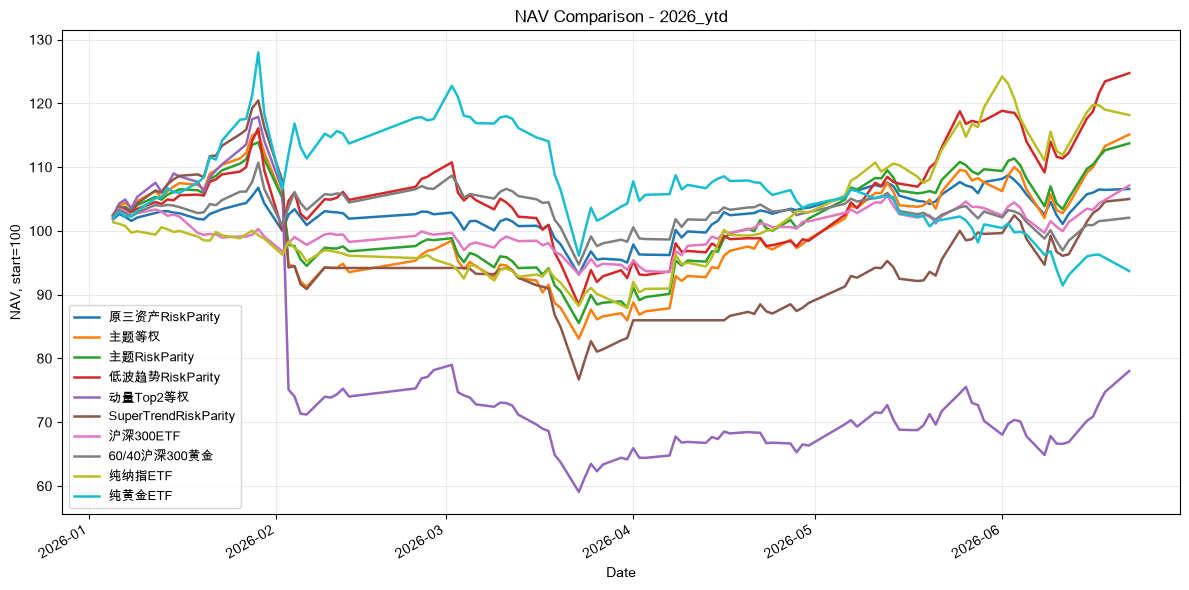

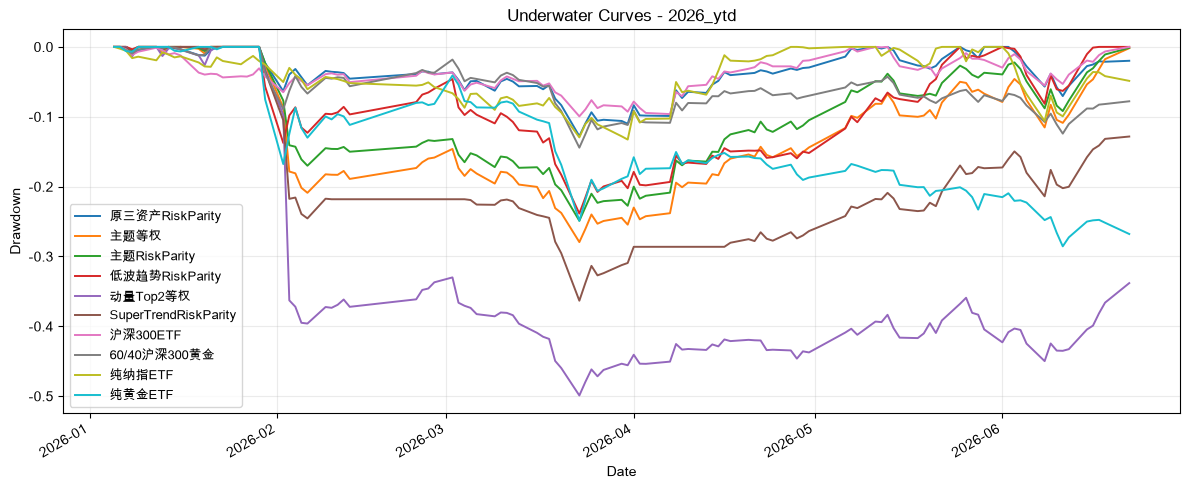

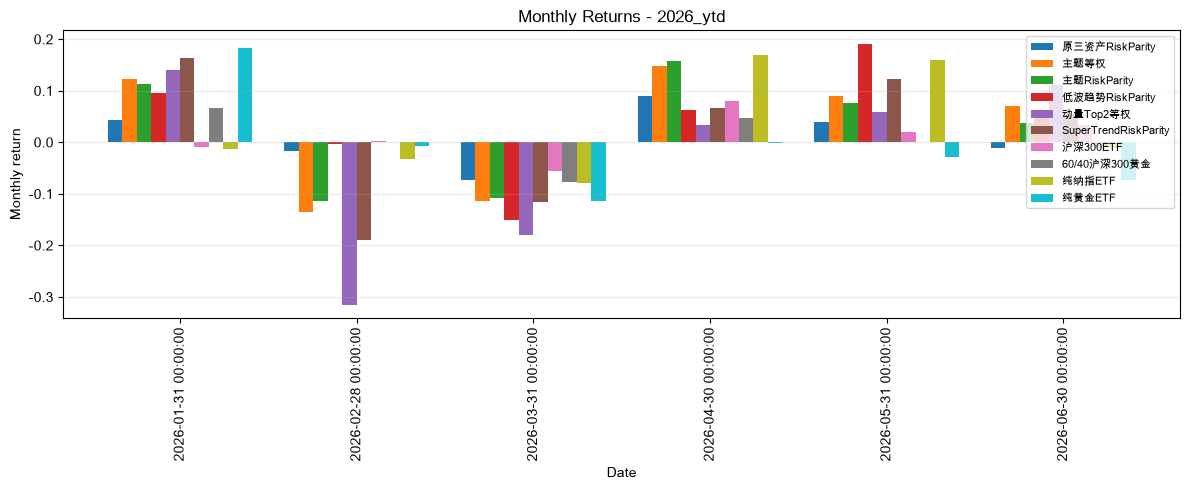

,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛
策略,,,,,,
低波趋势RiskParity,0.2474,0.6595,0.3470,-0.2385,1.9007,2.7646
纯纳指ETF,0.1817,0.4660,0.2679,-0.1326,1.7396,3.5130
主题RiskParity,0.1373,0.3428,0.2920,-0.2489,1.1739,1.3773
主题等权,0.1512,0.3806,0.3381,-0.2794,1.1257,1.3622
沪深300ETF,0.0711,0.1704,0.1718,-0.0994,0.9923,1.7145
原三资产RiskParity,0.0658,0.1572,0.2060,-0.1278,0.7630,1.2300
SuperTrendRiskParity,0.0500,0.1183,0.3773,-0.3633,0.3136,0.3257
60/40沪深300黄金,0.0207,0.0480,0.2285,-0.1442,0.2103,0.3331
纯黄金ETF,-0.0629,-0.1383,0.3807,-0.2855,-0.3632,-0.4844


,原三资产RiskParity,主题等权,主题RiskParity,低波趋势RiskParity,动量Top2等权,SuperTrendRiskParity,沪深300ETF,60/40沪深300黄金,纯纳指ETF,纯黄金ETF
Date,,,,,,,,,,
2026-01-31,0.0432,0.1227,0.1122,0.0949,0.1409,0.1628,-0.0088,0.0656,-0.0121,0.1836
2026-02-28,-0.0164,-0.1355,-0.1139,-0.0032,-0.3149,-0.1900,0.0030,0.0003,-0.0330,-0.0069
2026-03-31,-0.0738,-0.1140,-0.1072,-0.1515,-0.1790,-0.1167,-0.0554,-0.0777,-0.0797,-0.1129
2026-04-30,0.0905,0.1482,0.1585,0.0632,0.0337,0.0661,0.0809,0.0472,0.1703,-0.0022
2026-05-31,0.0389,0.0898,0.0759,0.1916,0.0585,0.1222,0.0205,0.0009,0.1603,-0.0290
2026-06-30,-0.0101,0.0698,0.0370,0.0633,0.1113,0.0549,0.0341,-0.0094,-0.0101,-0.0725



=== Evaluating 2025_to_date: 2025-01-01 to latest ===


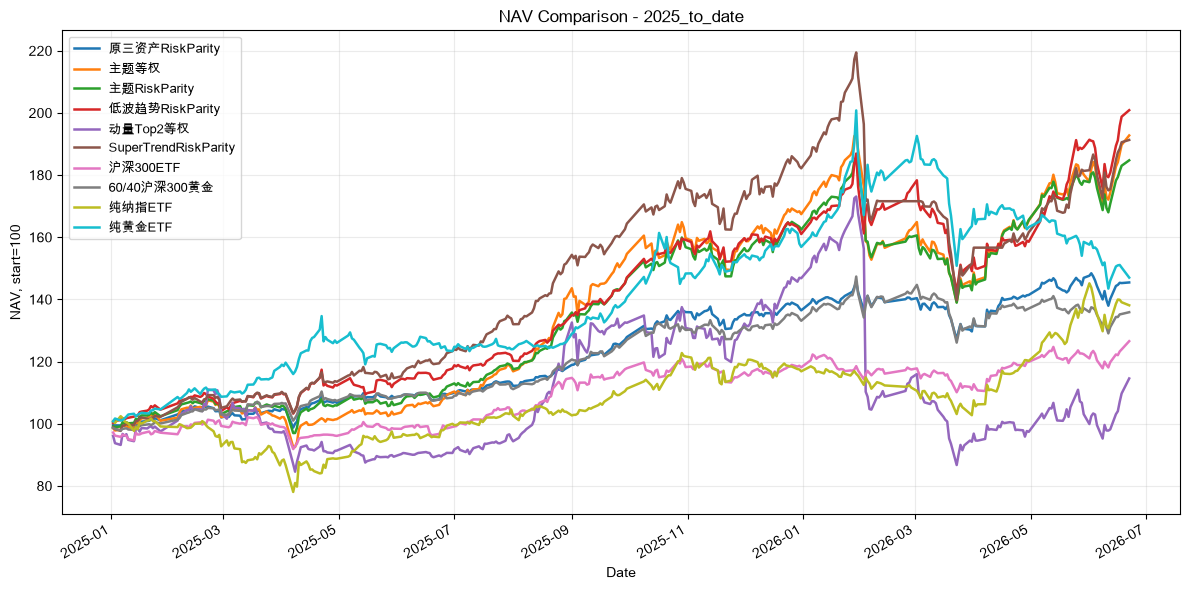

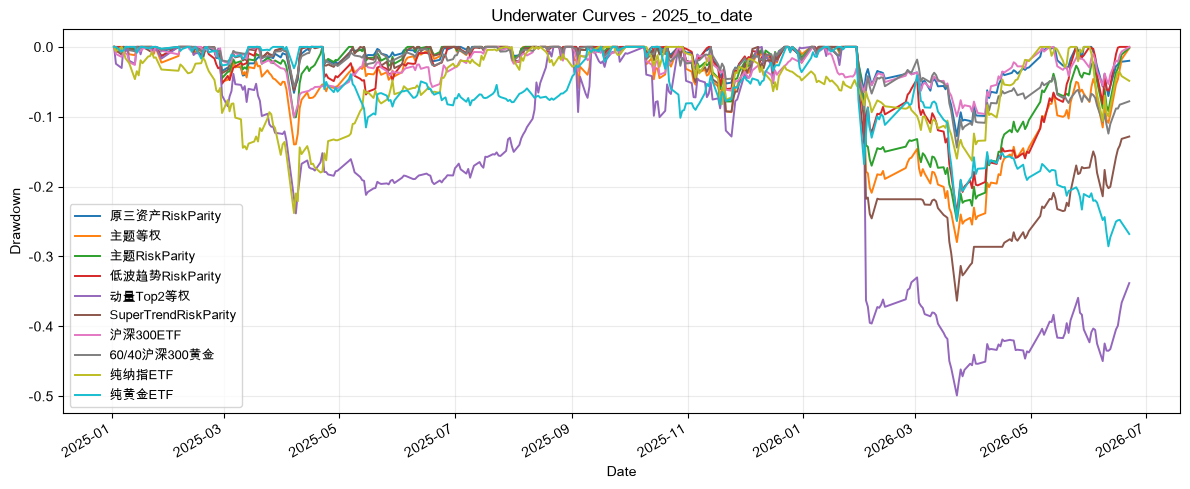

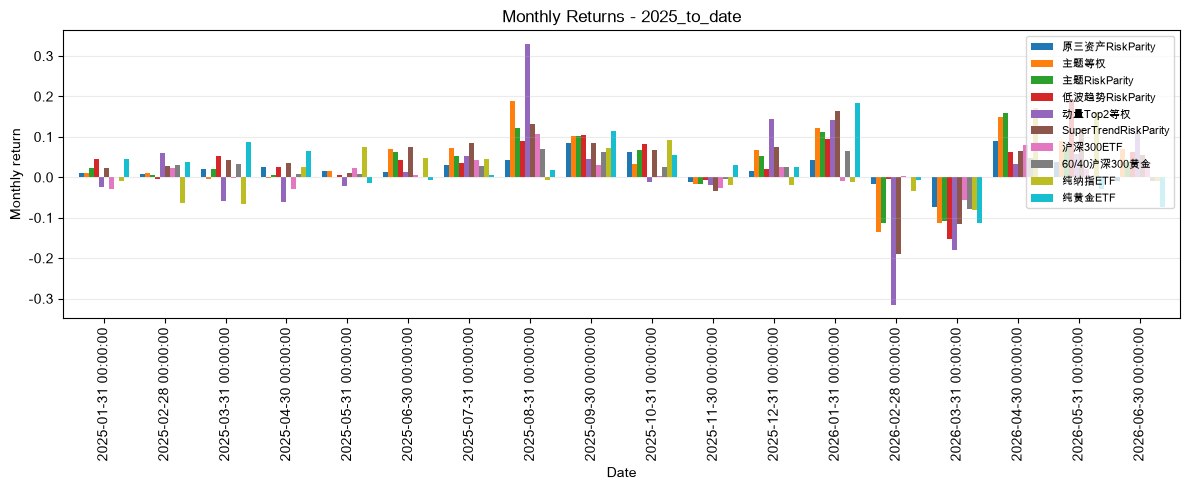

,累计收益,年化收益,年化波动,最大回撤,夏普,卡玛
策略,,,,,,
低波趋势RiskParity,1.0088,0.6477,0.2367,-0.2385,2.7365,2.7153
主题RiskParity,0.8476,0.5519,0.2191,-0.2489,2.5186,2.2177
主题等权,0.9275,0.5997,0.2608,-0.2794,2.2991,2.1463
SuperTrendRiskParity,0.9130,0.5911,0.2621,-0.3633,2.2555,1.6271
原三资产RiskParity,0.4547,0.3078,0.1563,-0.1278,1.9693,2.4087
60/40沪深300黄金,0.3590,0.2456,0.1658,-0.1442,1.4812,1.7028
纯黄金ETF,0.4703,0.3178,0.2649,-0.2855,1.1996,1.1133
沪深300ETF,0.2658,0.1838,0.1588,-0.1008,1.1575,1.8243
纯纳指ETF,0.3812,0.2601,0.2522,-0.2379,1.0314,1.0936


,原三资产RiskParity,主题等权,主题RiskParity,低波趋势RiskParity,动量Top2等权,SuperTrendRiskParity,沪深300ETF,60/40沪深300黄金,纯纳指ETF,纯黄金ETF
Date,,,,,,,,,,
2025-01-31,0.0114,0.0098,0.0242,0.0455,-0.0245,0.0224,-0.0286,0.0011,-0.0086,0.0462
2025-02-28,0.0090,0.0117,0.0063,-0.0040,0.0593,0.0284,0.0223,0.0295,-0.0644,0.0390
2025-03-31,0.0204,-0.0049,0.0216,0.0523,-0.0587,0.0439,-0.0025,0.0331,-0.0662,0.0881
2025-04-30,0.0251,-0.0016,0.0056,0.0248,-0.0607,0.0344,-0.0296,0.0083,0.0248,0.0655
2025-05-31,0.0165,0.0148,0.0012,0.0050,-0.0214,0.0102,0.0241,0.0093,0.0761,-0.0137
2025-06-30,0.0121,0.0694,0.0635,0.0436,0.0134,0.0757,0.0058,0.0008,0.0469,-0.0075
2025-07-31,0.0304,0.0717,0.0536,0.0356,0.0517,0.0854,0.0434,0.0281,0.0460,0.0049
2025-08-31,0.0416,0.1887,0.1226,0.0909,0.3308,0.1319,0.1073,0.0712,-0.0070,0.0185
2025-09-30,0.0852,0.1021,0.1011,0.1054,0.0447,0.0845,0.0304,0.0636,0.0715,0.1139


In [7]:
def safe_filename(name):
    text = str(name)
    for ch in ['/', '\\', ':', '*', '?', '"', '<', '>', '|', ' ']:
        text = text.replace(ch, "_")
    return text


def slice_returns(port, start):
    r = port["returns"].loc[pd.Timestamp(start):].dropna()
    return r


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    return nav / nav.cummax() - 1.0


def calc_metrics(name, r, weights=None):
    nav = nav_from_returns(r)
    total_return = nav.iloc[-1] / INITIAL_NAV - 1.0 if len(nav) else np.nan
    ann_return = (1.0 + total_return) ** (TRADING_DAYS / len(r)) - 1.0 if len(r) > 0 else np.nan
    ann_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS) if len(r) > 1 else np.nan
    max_dd = drawdown_series(nav).min() if len(nav) else np.nan
    sharpe = ann_return / ann_vol if ann_vol and ann_vol > 0 else np.nan
    calmar = ann_return / abs(max_dd) if max_dd and max_dd < 0 else np.nan
    downside = r[r < 0].std(ddof=1) * np.sqrt(TRADING_DAYS)
    sortino = ann_return / downside if downside and downside > 0 else np.nan
    row = {
        "策略": name,
        "累计收益": total_return,
        "年化收益": ann_return,
        "年化波动": ann_vol,
        "最大回撤": max_dd,
        "夏普": sharpe,
        "卡玛": calmar,
        "索提诺": sortino,
    }
    if weights is not None and not weights.empty:
        for sym in COMMON_SYMBOLS:
            col = SYMBOL_NAMES.get(sym, sym)
            if sym in weights.columns:
                row[f"当前权重_{col}"] = weights[sym].iloc[-1]
                row[f"平均权重_{col}"] = weights[sym].mean()
        if "CASH" in weights.columns:
            row["当前现金"] = weights["CASH"].iloc[-1]
            row["平均现金"] = weights["CASH"].mean()
    return row


def monthly_returns(r):
    return r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)


def annual_returns(r):
    return r.resample("YE").apply(lambda x: (1.0 + x).prod() - 1.0)


def monthly_stats(name, r):
    m = monthly_returns(r).dropna()
    wins = m[m > 0]
    losses = m[m < 0]
    avg_win = wins.mean() if len(wins) else np.nan
    avg_loss = losses.mean() if len(losses) else np.nan
    return {
        "策略": name,
        "月胜率": (m > 0).mean() if len(m) else np.nan,
        "平均盈利月": avg_win,
        "平均亏损月": avg_loss,
        "盈亏比": avg_win / abs(avg_loss) if pd.notna(avg_win) and pd.notna(avg_loss) and avg_loss != 0 else np.nan,
        "盈亏因子": wins.sum() / abs(losses.sum()) if len(losses) and losses.sum() != 0 else np.nan,
        "最好月份": m.max() if len(m) else np.nan,
        "最差月份": m.min() if len(m) else np.nan,
    }


def drawdown_events(nav):
    dd = drawdown_series(nav)
    events = []
    in_dd = False
    peak_date = nav.index[0]
    start = None
    trough = None
    trough_dd = 0.0
    for date, value in dd.items():
        if value < 0 and not in_dd:
            in_dd = True
            start = date
            peak_date = nav.loc[:date].idxmax()
            trough = date
            trough_dd = value
        elif value < 0 and in_dd:
            if value < trough_dd:
                trough_dd = value
                trough = date
        elif value >= 0 and in_dd:
            recovery = date
            events.append({
                "peak_date": peak_date,
                "start_date": start,
                "trough_date": trough,
                "recovery_date": recovery,
                "depth": trough_dd,
                "days_to_trough": (trough - start).days,
                "days_to_recovery": (recovery - start).days,
                "recovered": True,
            })
            in_dd = False
    if in_dd:
        events.append({
            "peak_date": peak_date,
            "start_date": start,
            "trough_date": trough,
            "recovery_date": pd.NaT,
            "depth": trough_dd,
            "days_to_trough": (trough - start).days,
            "days_to_recovery": np.nan,
            "recovered": False,
        })
    return pd.DataFrame(events).sort_values("depth") if events else pd.DataFrame(
        columns=["peak_date", "start_date", "trough_date", "recovery_date", "depth", "days_to_trough", "days_to_recovery", "recovered"]
    )


def evaluate_window(window_name, start):
    out_dir = OUTPUT_DIR / window_name
    out_dir.mkdir(parents=True, exist_ok=True)

    sliced_returns = {name: slice_returns(port, start) for name, port in all_portfolios.items()}
    sliced_returns = {name: r for name, r in sliced_returns.items() if len(r) > 20}

    navs = pd.DataFrame({name: nav_from_returns(r) for name, r in sliced_returns.items()})
    underwater = navs.apply(drawdown_series)
    monthly = pd.DataFrame({name: monthly_returns(r) for name, r in sliced_returns.items()})
    annual = pd.DataFrame({name: annual_returns(r) for name, r in sliced_returns.items()})

    q3_rows = []
    q5_rows = []
    monthly_rows = []
    dd_summary_rows = []
    latest_weight_rows = []
    avg_weight_rows = []

    baseline_r = sliced_returns.get("原三资产RiskParity")
    hs300_r = sliced_returns.get("沪深300ETF")

    for name, r in sliced_returns.items():
        port = all_portfolios[name]
        w = port["weights"].loc[r.index]
        metrics = calc_metrics(name, r, w)
        q3_rows.append(metrics)
        mstats = monthly_stats(name, r)
        q5 = {**metrics, **mstats}
        if baseline_r is not None and name != "原三资产RiskParity":
            aligned = pd.concat([r, baseline_r], axis=1).dropna()
            q5["Alpha_vs_原三资产RiskParity"] = (1 + aligned.iloc[:, 0]).prod() - (1 + aligned.iloc[:, 1]).prod()
        else:
            q5["Alpha_vs_原三资产RiskParity"] = 0.0 if name == "原三资产RiskParity" else np.nan
        if hs300_r is not None:
            aligned = pd.concat([r, hs300_r], axis=1).dropna()
            q5["Alpha_vs_沪深300ETF"] = (1 + aligned.iloc[:, 0]).prod() - (1 + aligned.iloc[:, 1]).prod()
        q5_rows.append(q5)
        monthly_rows.append(mstats)

        events = drawdown_events(nav_from_returns(r))
        events.to_csv(out_dir / f"drawdown_events_{safe_filename(name)}.csv", index=False, encoding="utf-8-sig")
        dd = drawdown_series(nav_from_returns(r))
        dd_summary_rows.append({
            "策略": name,
            "最大水下": dd.min(),
            "平均水下": dd[dd < 0].mean(),
            "当前水下": dd.iloc[-1],
            "回撤事件数": len(events),
            "最深回撤恢复天数": events.iloc[0]["days_to_recovery"] if len(events) else np.nan,
            "最长恢复天数": events["days_to_recovery"].max() if len(events) else np.nan,
        })

        weight_cols = [sym for sym in COMMON_SYMBOLS if sym in w.columns]
        latest_weight_rows.append({"策略": name, **{SYMBOL_NAMES.get(sym, sym): w[sym].iloc[-1] for sym in weight_cols}, "现金": w["CASH"].iloc[-1] if "CASH" in w else 0.0})
        avg_weight_rows.append({"策略": name, **{SYMBOL_NAMES.get(sym, sym): w[sym].mean() for sym in weight_cols}, "现金": w["CASH"].mean() if "CASH" in w else 0.0})

    q3 = pd.DataFrame(q3_rows).set_index("策略").sort_values("夏普", ascending=False)
    q5 = pd.DataFrame(q5_rows).set_index("策略").sort_values("夏普", ascending=False)
    mstats = pd.DataFrame(monthly_rows).set_index("策略").reindex(q3.index)
    dd_summary = pd.DataFrame(dd_summary_rows).set_index("策略").reindex(q3.index)
    latest_weights = pd.DataFrame(latest_weight_rows).set_index("策略").reindex(q3.index)
    avg_weights = pd.DataFrame(avg_weight_rows).set_index("策略").reindex(q3.index)

    q3.to_csv(out_dir / "q3_metrics.csv", encoding="utf-8-sig")
    q5.to_csv(out_dir / "q5_metrics.csv", encoding="utf-8-sig")
    monthly.to_csv(out_dir / "monthly_returns.csv", encoding="utf-8-sig")
    annual.to_csv(out_dir / "annual_returns.csv", encoding="utf-8-sig")
    mstats.to_csv(out_dir / "monthly_stats.csv", encoding="utf-8-sig")
    dd_summary.to_csv(out_dir / "drawdown_summary.csv", encoding="utf-8-sig")
    underwater.to_csv(out_dir / "underwater_curves.csv", encoding="utf-8-sig")
    latest_weights.to_csv(out_dir / "latest_weights.csv", encoding="utf-8-sig")
    avg_weights.to_csv(out_dir / "average_weights.csv", encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(12, 6))
    navs.plot(ax=ax, linewidth=1.8)
    ax.set_title(f"NAV Comparison - {window_name}")
    ax.set_ylabel("NAV, start=100")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best", fontsize=9)
    fig.tight_layout()
    fig.savefig(out_dir / "nav_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    underwater.plot(ax=ax, linewidth=1.4)
    ax.set_title(f"Underwater Curves - {window_name}")
    ax.set_ylabel("Drawdown")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best", fontsize=9)
    fig.tight_layout()
    fig.savefig(out_dir / "underwater_curves.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    monthly.plot(kind="bar", ax=ax, width=0.82)
    ax.set_title(f"Monthly Returns - {window_name}")
    ax.set_ylabel("Monthly return")
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(out_dir / "monthly_returns.png", dpi=160, bbox_inches="tight")
    plt.show()

    result = {
        "window": window_name,
        "start": start,
        "end": str(max(r.index.max() for r in sliced_returns.values()).date()),
        "q3": q3,
        "q5": q5,
        "monthly": monthly,
        "annual": annual,
        "drawdown_summary": dd_summary,
        "latest_weights": latest_weights,
        "average_weights": avg_weights,
    }
    return result

window_results = {}
for window_name, start in EVAL_WINDOWS.items():
    print(f"\n=== Evaluating {window_name}: {start} to latest ===")
    window_results[window_name] = evaluate_window(window_name, start)
    display(window_results[window_name]["q3"][["累计收益", "年化收益", "年化波动", "最大回撤", "夏普", "卡玛"]].round(4))
    display(window_results[window_name]["monthly"].round(4))


## 7. Parameter Sensitivity

小网格只用于看结果形状，不用于挑最漂亮参数。


In [8]:
def metric_for_sensitivity(port, start="2025-01-01"):
    r = slice_returns(port, start)
    row = calc_metrics(port["name"], r, port["weights"].loc[r.index])
    return row

sens_rows = []
for vol_window in [10, 20, 40, 60]:
    port = run_strategy(f"主题RP_vol{vol_window}", THEME_ASSETS, all_assets_selector(THEME_ASSETS), rp_allocator(THEME_ASSETS, vol_window))
    row = metric_for_sensitivity(port, "2025-01-01")
    row.update({"类别": "risk_parity_vol", "参数1": vol_window, "参数2": np.nan})
    sens_rows.append(row)

for lookback in [63, 126, 189, 252]:
    for top_n in [1, 2, 3]:
        port = run_strategy(f"MOM{lookback}_top{top_n}", THEME_ASSETS, momentum_selector(THEME_ASSETS, lookback, top_n), ew_allocator(THEME_ASSETS))
        row = metric_for_sensitivity(port, "2025-01-01")
        row.update({"类别": "momentum", "参数1": lookback, "参数2": top_n})
        sens_rows.append(row)

for ma_window in [60, 120, 180, 200]:
    port = run_strategy(f"LowVolTrend_MA{ma_window}", THEME_ASSETS, low_vol_trend_selector(THEME_ASSETS, ma_window=ma_window), rp_allocator(THEME_ASSETS, BASE_VOL_WINDOW))
    row = metric_for_sensitivity(port, "2025-01-01")
    row.update({"类别": "low_vol_trend", "参数1": ma_window, "参数2": LOW_VOL_TOP_N})
    sens_rows.append(row)

for atr in [7, 10, 14]:
    for mult in [2.0, 3.0, 4.0]:
        port = run_strategy(f"ST{atr}_{mult:g}", THEME_ASSETS, supertrend_selector(THEME_ASSETS, atr, mult), rp_allocator(THEME_ASSETS, BASE_VOL_WINDOW))
        row = metric_for_sensitivity(port, "2025-01-01")
        row.update({"类别": "supertrend", "参数1": atr, "参数2": mult})
        sens_rows.append(row)

sensitivity = pd.DataFrame(sens_rows).set_index(["类别", "参数1", "参数2", "策略"]).sort_values("夏普", ascending=False)
sensitivity.to_csv(OUTPUT_DIR / "sensitivity_2025_to_date.csv", encoding="utf-8-sig")
display(sensitivity[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "平均现金"]].round(4).head(30))


累计收益    年化收益    最大回撤      夏普  \
类别              参数1 参数2 策略                                                  
supertrend      7   3.0 ST7_3              1.3365  0.8360 -0.2455  3.5112   
                10  4.0 ST10_4             1.4189  0.8821 -0.2631  3.4174   
                7   4.0 ST7_4              1.3079  0.8198 -0.2664  3.0956   
low_vol_trend   60  3.0 LowVolTrend_MA60   1.2332  0.7775 -0.2942  3.0736   
supertrend      14  4.0 ST14_4             1.3156  0.8242 -0.3999  2.9304   
low_vol_trend   120 3.0 LowVolTrend_MA120  1.0088  0.6477 -0.2385  2.7365   
risk_parity_vol 40  NaN 主题RP_vol40         0.9235  0.5973 -0.2363  2.7310   
                60  NaN 主题RP_vol60         0.9421  0.6083 -0.2464  2.7266   
low_vol_trend   200 3.0 LowVolTrend_MA200  0.9760  0.6284 -0.2385  2.6646   
                180 3.0 LowVolTrend_MA180  0.9760  0.6284 -0.2385  2.6646   
momentum        63  1.0 MOM63_top1         1.8461  1.1145 -0.2975  2.6189   
risk_parity_vol 20  NaN 主题RP_vol20         0.8476  0.5519 -0.2489  2.5186   
supertrend      10  2.0 ST10_2             0.9135  0.5914 -0.2905  2.4365   
                14  3.0 ST14_3             0.8696  0.5651 -0.3321  2.3932   
risk_parity_vol 10  NaN 主题RP_vol10         0.8154  0.5325 -0.2606  2.3921   
supertrend      14  2.0 ST14_2             0.9426  0.6087 -0.2698  2.3240   
                7   2.0 ST7_2              0.8801  0.5714 -0.2905  2.3003   
                10  3.0 ST10_3             0.9130  0.5911 -0.3633  2.2555   
momentum        63  2.0 MOM63_top2         1.1414  0.7248 -0.2724  2.0758   
                    3.0 MOM63_top3         0.8461  0.5510 -0.3914  1.6283   
                252 3.0 MOM252_top3        0.7943  0.5197 -0.3914  1.5511   
                    2.0 MOM252_top2        0.6535  0.4334 -0.4767  1.0097   
                189 3.0 MOM189_top3        0.4222  0.2868 -0.3843  0.8932   
                126 3.0 MOM126_top3        0.4109  0.2795 -0.3843  0.8301   
                189 2.0 MOM189_top2        0.4857  0.3277 -0.4684  0.8137   
                126 2.0 MOM126_top2        0.1459  0.1024 -0.4989  0.2426   
                252 1.0 MOM252_top1       -0.2280 -0.1691 -0.7276 -0.2432   
                189 1.0 MOM189_top1       -0.3521 -0.2671 -0.7276 -0.3801   
                126 1.0 MOM126_top1       -0.3564 -0.2705 -0.7386 -0.3824   

                                               卡玛    平均现金  
类别              参数1 参数2 策略                                 
supertrend      7   3.0 ST7_3              3.4053  0.1136  
                10  4.0 ST10_4             3.3527  0.0852  
                7   4.0 ST7_4              3.0778  0.0568  
low_vol_trend   60  3.0 LowVolTrend_MA60   2.6428  0.0284  
supertrend      14  4.0 ST14_4             2.0607  0.0284  
low_vol_trend   120 3.0 LowVolTrend_MA120  2.7153  0.0000  
risk_parity_vol 40  NaN 主题RP_vol40         2.5281  0.0000  
                60  NaN 主题RP_vol60         2.4692  0.0000  
low_vol_trend   200 3.0 LowVolTrend_MA200  2.6343  0.0000  
                180 3.0 LowVolTrend_MA180  2.6343  0.0000  
momentum        63  1.0 MOM63_top1         3.7462  0.0000  
risk_parity_vol 20  NaN 主题RP_vol20         2.2177  0.0000  
supertrend      10  2.0 ST10_2             2.0360  0.0852  
                14  3.0 ST14_3             1.7016  0.0568  
risk_parity_vol 10  NaN 主题RP_vol10         2.0435  0.0000  
supertrend      14  2.0 ST14_2             2.2561  0.0568  
                7   2.0 ST7_2              1.9672  0.0568  
                10  3.0 ST10_3             1.6271  0.0568  
momentum        63  2.0 MOM63_top2         2.6607  0.0000  
                    3.0 MOM63_top3         1.4077  0.0000  
                252 3.0 MOM252_top3        1.3277  0.0511  
                    2.0 MOM252_top2        0.9092  0.0511  
                189 3.0 MOM189_top3        0.7461  0.0000  
                126 3.0 MOM126_top3        0.7272  0.0000  
                189 2.0 MOM189_top2        0.6995  0.0000  
                126 2.0 MOM126_top2  

## 8. Plain-Language Conclusion

下面自动抽取历史收益最高、Sharpe 最高、Calmar 最高和当前权重，供人工复盘。最终判断不要只按单一指标排名。


In [9]:
summary_rows = []
for window_name, res in window_results.items():
    q3 = res["q3"]
    q5 = res["q5"]
    hist_best = q3["累计收益"].idxmax()
    sharpe_best = q3["夏普"].idxmax()
    calmar_best = q3["卡玛"].idxmax()
    min_dd = q3["最大回撤"].idxmax()  # less negative is better
    baseline = q3.loc["原三资产RiskParity"]
    summary_rows.append({
        "窗口": window_name,
        "开始": res["start"],
        "结束": res["end"],
        "历史收益最高": hist_best,
        "Sharpe最高": sharpe_best,
        "Calmar最高": calmar_best,
        "回撤最浅": min_dd,
        "原三资产RP累计收益": baseline["累计收益"],
        "原三资产RP最大回撤": baseline["最大回撤"],
        "原三资产RP夏普": baseline["夏普"],
    })

research_summary = pd.DataFrame(summary_rows)
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary)

for window_name, res in window_results.items():
    print(f"\n[{window_name}] conclusion prompts")
    print("Historical best:", res["q3"]["累计收益"].idxmax())
    print("Risk-adjusted best by Sharpe:", res["q3"]["夏普"].idxmax())
    print("Best drawdown/Calmar candidate:", res["q3"]["卡玛"].idxmax())
    print("Most structurally balanced candidate to review: compare 原三资产RiskParity vs 主题RiskParity vs 低波趋势RiskParity")
    print("Latest weights:")
    display(res["latest_weights"].round(4))


,窗口,开始,结束,历史收益最高,Sharpe最高,Calmar最高,回撤最浅,原三资产RP累计收益,原三资产RP最大回撤,原三资产RP夏普
0,2026_ytd,2026-01-01,2026-06-22,低波趋势RiskParity,低波趋势RiskParity,纯纳指ETF,沪深300ETF,0.065791,-0.127778,0.763048
1,2025_to_date,2025-01-01,2026-06-22,低波趋势RiskParity,低波趋势RiskParity,低波趋势RiskParity,沪深300ETF,0.454710,-0.127778,1.969286



[2026_ytd] conclusion prompts
Historical best: 低波趋势RiskParity
Risk-adjusted best by Sharpe: 低波趋势RiskParity
Best drawdown/Calmar candidate: 纯纳指ETF
Most structurally balanced candidate to review: compare 原三资产RiskParity vs 主题RiskParity vs 低波趋势RiskParity
Latest weights:


,沪深300ETF,纳指100ETF,黄金ETF,现金,有色金属ETF,芯片ETF,通信ETF
策略,,,,,,,
低波趋势RiskParity,NaN,0.5998,0.0000,0.0,0.0000,0.4002,0.0000
纯纳指ETF,0.000,1.0000,0.0000,0.0,0.0000,0.0000,0.0000
主题RiskParity,NaN,0.2144,0.3121,0.0,0.1885,0.1430,0.1420
主题等权,NaN,0.2000,0.2000,0.0,0.2000,0.2000,0.2000
沪深300ETF,1.000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
原三资产RiskParity,0.459,0.2203,0.3207,0.0,NaN,NaN,NaN
SuperTrendRiskParity,NaN,0.6015,0.0000,0.0,0.0000,0.0000,0.3985
60/40沪深300黄金,0.600,0.0000,0.4000,0.0,0.0000,0.0000,0.0000
纯黄金ETF,0.000,0.0000,1.0000,0.0,0.0000,0.0000,0.0000



[2025_to_date] conclusion prompts
Historical best: 低波趋势RiskParity
Risk-adjusted best by Sharpe: 低波趋势RiskParity
Best drawdown/Calmar candidate: 低波趋势RiskParity
Most structurally balanced candidate to review: compare 原三资产RiskParity vs 主题RiskParity vs 低波趋势RiskParity
Latest weights:


,沪深300ETF,纳指100ETF,黄金ETF,现金,有色金属ETF,芯片ETF,通信ETF
策略,,,,,,,
低波趋势RiskParity,NaN,0.5998,0.0000,0.0,0.0000,0.4002,0.0000
主题RiskParity,NaN,0.2144,0.3121,0.0,0.1885,0.1430,0.1420
主题等权,NaN,0.2000,0.2000,0.0,0.2000,0.2000,0.2000
SuperTrendRiskParity,NaN,0.6015,0.0000,0.0,0.0000,0.0000,0.3985
原三资产RiskParity,0.459,0.2203,0.3207,0.0,NaN,NaN,NaN
60/40沪深300黄金,0.600,0.0000,0.4000,0.0,0.0000,0.0000,0.0000
纯黄金ETF,0.000,0.0000,1.0000,0.0,0.0000,0.0000,0.0000
沪深300ETF,1.000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
纯纳指ETF,0.000,1.0000,0.0000,0.0,0.0000,0.0000,0.0000
